Public-contract revision 2026-10-29

V2 replaces sampled-response/finite-fusion array identity with the original measured-code RMS limit7.105642315376502ADU, monotonicity/midpoint gauge and a public log-response second-difference regularity class. No actual irradiance/response truth exists. Independent full-observation Schur-complement photometric LS and log fusion, without source or hidden response in the solve, reaches5.45973770163ADU and curvature.000182705876 versus allowed.001757587274. Both outputs remain evaluated jointly by their forward predictions. Source/output arrays unchanged. Earlier array-agreement diagnostics are historical v1 parity measurements.

# Joint camera response and bracketed irradiance

## Problem
Recover the original relative illumination field and unknown camera encoding from seven **real photographs**. The exposure bracket spans8000:1 in shutter time. Bright-window saturation and dark indoor regions cannot be recovered reliably from one exposure. The output is photometric irradiance plus response, not a tone-mapped photograph.

This notebook actively reconstructs the full427×640 RGB acquisition. **Independent GT is unavailable.** Original-code results are method references; their agreement is not physical truth. Tone maps are clearly separated from quantitative arrays.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
root=Path.cwd()
if not (root/'src').exists(): root=root.parent
os.chdir(root)
if str(root) not in sys.path: sys.path.insert(0,str(root))
from src.preprocessing import load_observations,sample_stack
from src.solvers import reconstruct,fit_response,merge_exposures
from src.physics_model import predict_codes,forward_residual,log_exposure_residual
from src.visualization import display_rgb,agreement
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
frames,times=load_observations()
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f: upstream={k:f[k].copy() for k in f.files}
with np.load('notebooks/reference_outputs/upstream_comparisons.npz',allow_pickle=False) as f: upstream_baselines={k:f[k].copy() for k in f.files}


## Data
The author-deposited JPEG stack carries Canon EOS REBEL T2i EXIF metadata:2015-08-21,36mm focal length,f/4.5 andISO200. Actual shutter times are2,0.5,0.125,1/30,0.008,0.001 and0.00025seconds. These are already processed, reduced-resolution photographs; native sensor RAW and a measured camera-noise model are unavailable. We preserve every deposited pixel and the exact exposure values. No response or irradiance estimate is provided as public calibration.

The array shape is(1,7,427,640,3),uint8 ADU. The timestamps span roughly101seconds, so perfect scene constancy is an approximation. The final panel below summarizes measured saturation, not simulated corruption.

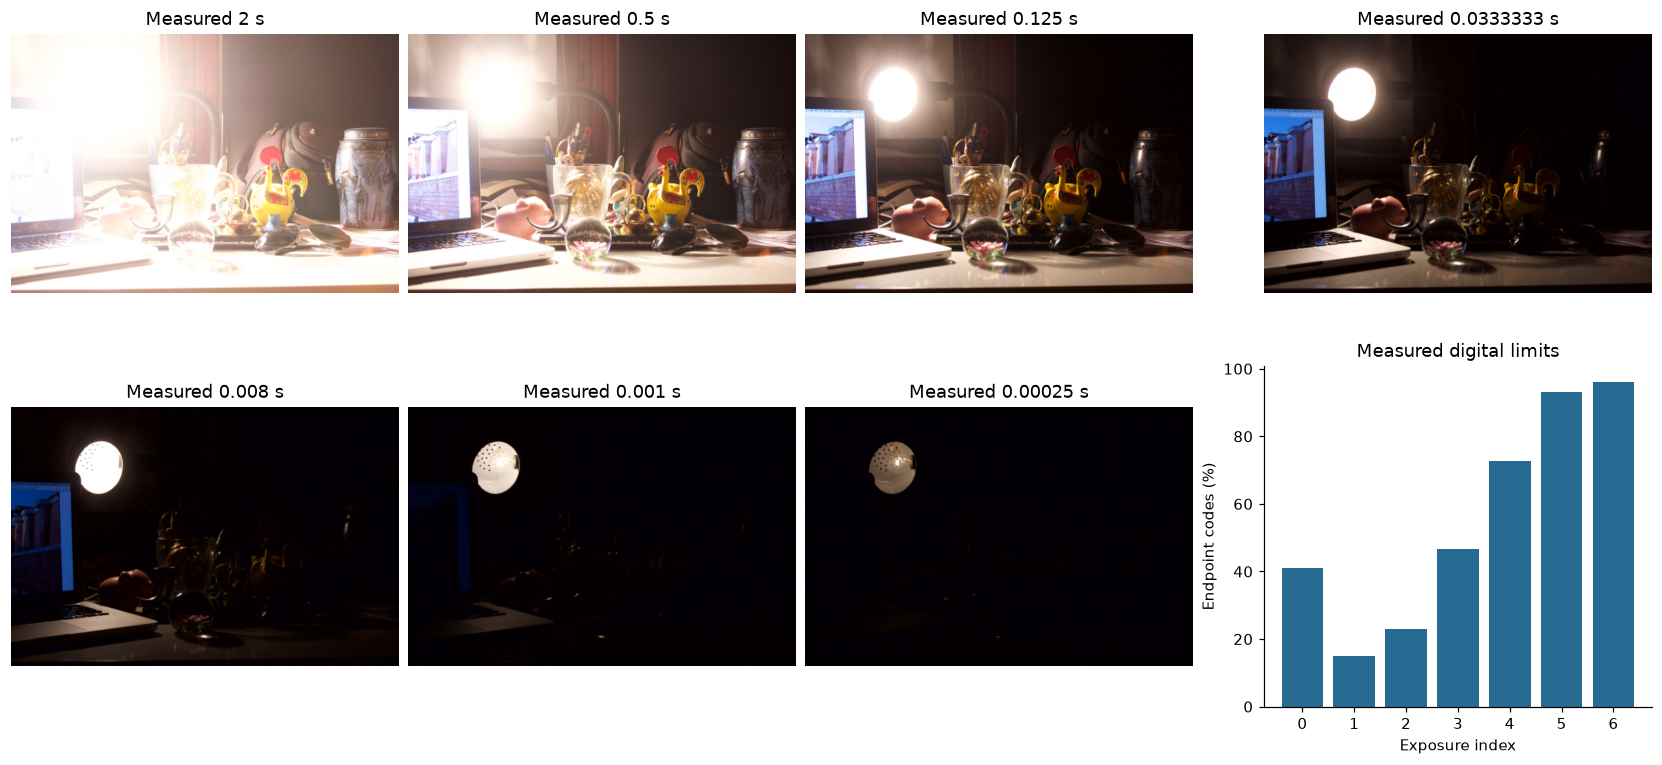

In [2]:
fig,axs=plt.subplots(2,4,figsize=(15,7),layout='constrained')
for j,ax in enumerate(axs.flat[:7]):
    ax.imshow(frames[j]);ax.set_title(f'Measured {times[j]:.6g} s');ax.axis('off')
obs_saturation=np.mean((frames<=7)|(frames>=248),axis=(1,2,3))
axs.flat[7].bar(np.arange(7),obs_saturation*100,color='#276b93')
axs.flat[7].set(xlabel='Exposure index',ylabel='Endpoint codes (%)',title='Measured digital limits')
plt.show()


## Physics
For exposure j,pixel p and channel c,the camera records z≈Q(f(E t))+noise. E is relative irradiance,t is shutter time,f is the unknown nonlinear response,and Q digitizes/clips the code. In log inverse coordinates g=log(f inverse),

$$g_c(z_{jpc})\simeq\log E_{pc}+\log t_j.$$

We fix g(128)=0 independently in each channel. This gauge defines relative exposure; it does not calibrate watts or a physically known white balance. Saturated codes do not determine the true exposure above clipping. Predicted digital values are obtained by inverting the recovered monotone response. A persistent residual can indicate JPEG processing, exposure inconsistency or scene changes; it cannot be called photon noise without additional calibration.

## Method
The regular grid supplies observation-only response samples; retain a site if any channel decreases strictly with decreasing exposure. For each channel solve the weighted least-squares system for g and sampled log irradiances ell. With w(z)=2min(z/255,1−z/255),lambda=128,the objective is

$$\sum_{ij}w(z_{ij})^2[g(z_{ij})-\ell_i-\log t_j]^2+g(128)^2+\lambda^2\sum_{z=1}^{254}w(z)^2[g(z-1)-2g(z)+g(z+1)]^2.$$

The full system is implemented locally and solved by a general LAPACK least-squares primitive. We then fuse all exposure-corrected log measurements at every pixel. The selected reference implementation adds1/65535 before the logarithm,uses special weights for extreme exposures and accumulates in float32; these conventions are preserved. We use the paper midpoint gauge directly,without the optional toolbox chromaticity-rescaling wrapper. All baseline and sensitivity reconstructions below execute local functions.

In [3]:
start=time.perf_counter()
fresh=reconstruct(frames,times)
runtime=time.perf_counter()-start
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',**fresh)
irradiance=fresh['reconstruction'][0];response=fresh['response'][0]
import subprocess
run=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
assert run.returncode==0,(run.stdout,run.stderr)
report=json.loads(Path('output/judge_report.json').read_text())
display(Markdown(f'Fresh complete reconstruction: **{runtime:.3f}s**. Kept **{len(sample_stack(frames,times))}** response sites. Judge: **{report["status"]}**.'))
print(json.dumps(report['metrics'],indent=2))


Fresh complete reconstruction: **0.200s**. Kept **65** response sites. Judge: **pass**.

{
  "ncc": 0.9999999999999044,
  "radiance_log_rmse": 1.1284761783040813e-07,
  "response_log_rmse": 1.0100545386476288e-12,
  "gauge_max_error": 3.375077994860476e-14,
  "forward_weighted_adu_rmse": 7.035289489025793
}


## Results
First compare the fresh response and full irradiance with this task's independently rerun original code. These are newly measured numerical comparisons,not paper scores. The response curves expose the blind photometric inverse; the log irradiance image retains the dynamic range hidden by the JPEG previews.

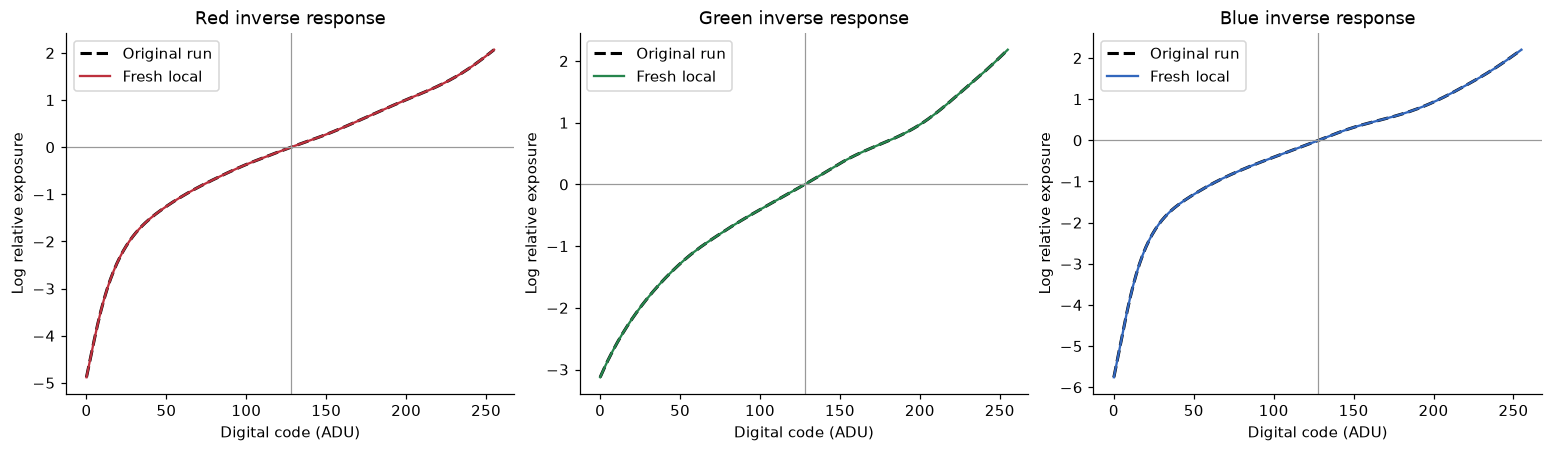

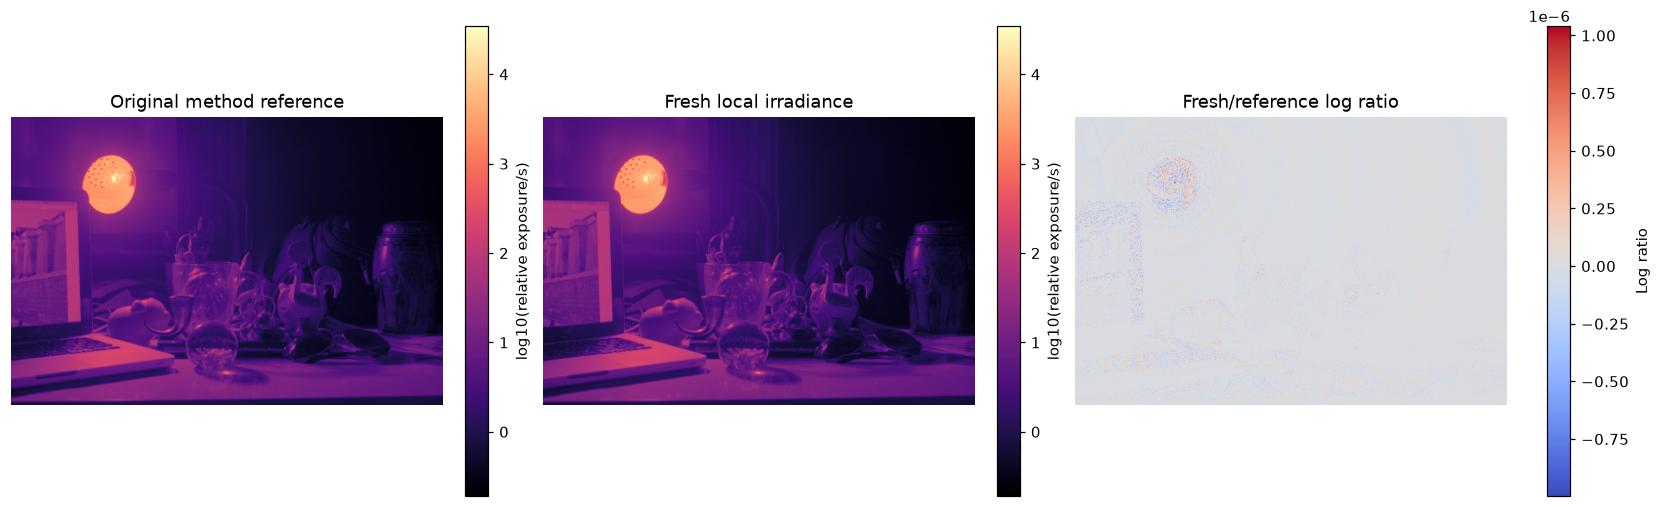

In [4]:
fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for c,(ax,color,label) in enumerate(zip(axs,['#bd303d','#26854d','#3267bd'],['Red','Green','Blue'])):
    ax.plot(np.arange(256),np.log(upstream['response'][0,:,c]),'k--',lw=2,label='Original run')
    ax.plot(np.arange(256),np.log(response[:,c]),color=color,label='Fresh local')
    ax.axvline(128,color='.6',lw=.8);ax.axhline(0,color='.6',lw=.8)
    ax.set(xlabel='Digital code (ADU)',ylabel='Log relative exposure',title=f'{label} inverse response');ax.legend()
plt.show()
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
lum=np.mean(irradiance,axis=2);ul=np.mean(upstream['reconstruction'][0],axis=2)
lo,hi=np.min(np.log10(ul)),np.max(np.log10(ul))
for ax,a,label in zip(axs[:2],[ul,lum],['Original method reference','Fresh local irradiance']):
    im=ax.imshow(np.log10(a),cmap='magma',vmin=lo,vmax=hi);ax.set_title(label);ax.axis('off');fig.colorbar(im,ax=ax,label='log10(relative exposure/s)')
im=axs[2].imshow(np.log(lum/ul),cmap='coolwarm');axs[2].set_title('Fresh/reference log ratio');axs[2].axis('off');fig.colorbar(im,ax=axs[2],label='Log ratio')
plt.show()


### Reconstructing with an incorrect response
The linear and gamma2.2 baselines are genuine new full-image merges,also compared numerically with their archived original runs. Display exposure is normalized separately by each image's geometric-mean luminance. This display convention makes structure visible;it is not used by the Judge and cannot hide photometric error in the machine-readable submission.

Fresh baseline versus corresponding original run: {
  "linear": {
    "ncc": 0.9999999999999913,
    "log_rmse": 9.129854504332294e-08
  },
  "gamma": {
    "ncc": 0.9999999999999926,
    "log_rmse": 1.0464015604154186e-07
  }
}


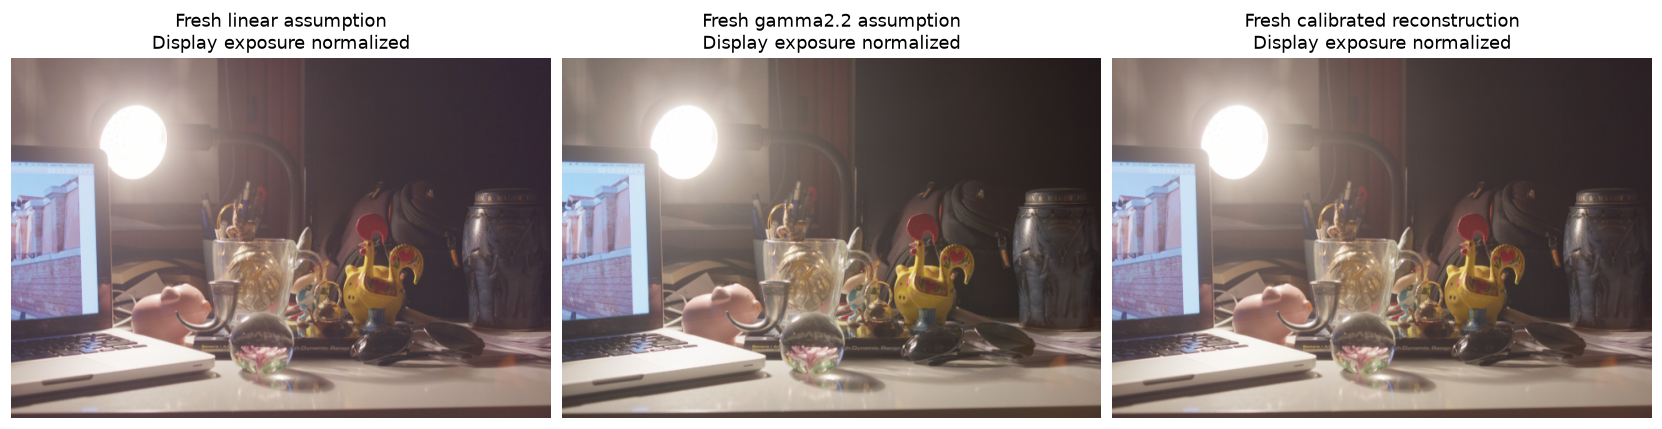

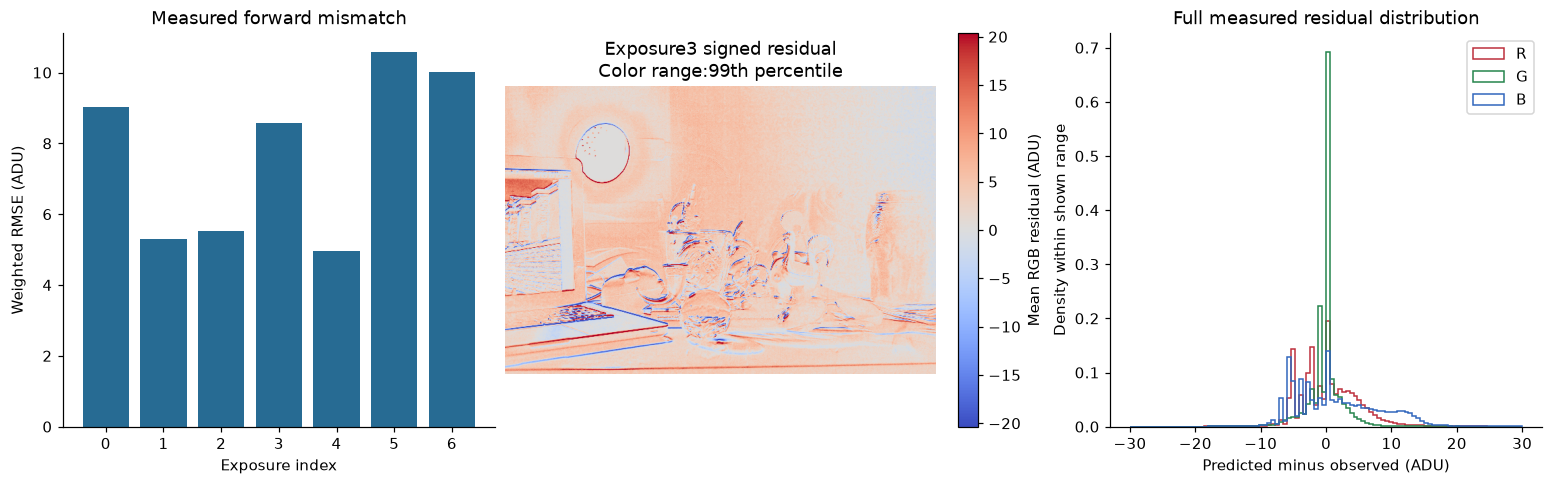

In [5]:
baselines={mode:merge_exposures(frames,times,mode=mode) for mode in ['linear','gamma']}
baseline_parity={m:agreement(a,upstream_baselines[m][0]) for m,a in baselines.items()}
print('Fresh baseline versus corresponding original run:',json.dumps(baseline_parity,indent=2))
fig,axs=plt.subplots(1,3,figsize=(15,5),layout='constrained')
for ax,a,label in zip(axs,[baselines['linear'],baselines['gamma'],irradiance],['Fresh linear assumption','Fresh gamma2.2 assumption','Fresh calibrated reconstruction']):
    ax.imshow(display_rgb(a));ax.set_title(label+'\nDisplay exposure normalized');ax.axis('off')
plt.show()
pred=predict_codes(irradiance,response,times)
per_exposure=[]
for j in range(7):
    z=frames[j].astype(float);w=np.minimum(z,255-z)*((z>=8)&(z<=247));per_exposure.append(float(np.sqrt(np.sum(w*(pred[j]-z)**2)/w.sum())))
fig,axs=plt.subplots(1,3,figsize=(14,4.3),layout='constrained')
axs[0].bar(np.arange(7),per_exposure,color='#276b93');axs[0].set(xlabel='Exposure index',ylabel='Weighted RMSE (ADU)',title='Measured forward mismatch')
res=np.mean(pred[3]-frames[3],axis=2);limit=np.percentile(np.abs(res),99)
im=axs[1].imshow(res,cmap='coolwarm',vmin=-limit,vmax=limit);fig.colorbar(im,ax=axs[1],label='Mean RGB residual (ADU)');axs[1].axis('off');axs[1].set_title('Exposure3 signed residual\nColor range:99th percentile')
for c,color in enumerate(['#bd303d','#26854d','#3267bd']):axs[2].hist((pred[...,c]-frames[...,c]).ravel(),bins=100,range=(-30,30),histtype='step',color=color,label='RGB'[c],density=True)
axs[2].set(xlabel='Predicted minus observed (ADU)',ylabel='Density within shown range',title='Full measured residual distribution');axs[2].legend();plt.show()


### Regularization, sampling and exposure coverage
All reconstructions in these comparisons are recomputed. We vary the response smoothness or requested grid density while retaining the same complete measured exposure stack. A trial curve can become nonmonotone because the selected published least-squares method does not impose monotonicity. Those failures remain visible as crosses and explicit flags;their log-exposure residual is defined,but inverse-code prediction is not. The exposure-subset experiment refits both unknowns from each selected subset;agreement is measured against the full-data method result,not GT. Subsets are selected by index coverage before fitting.

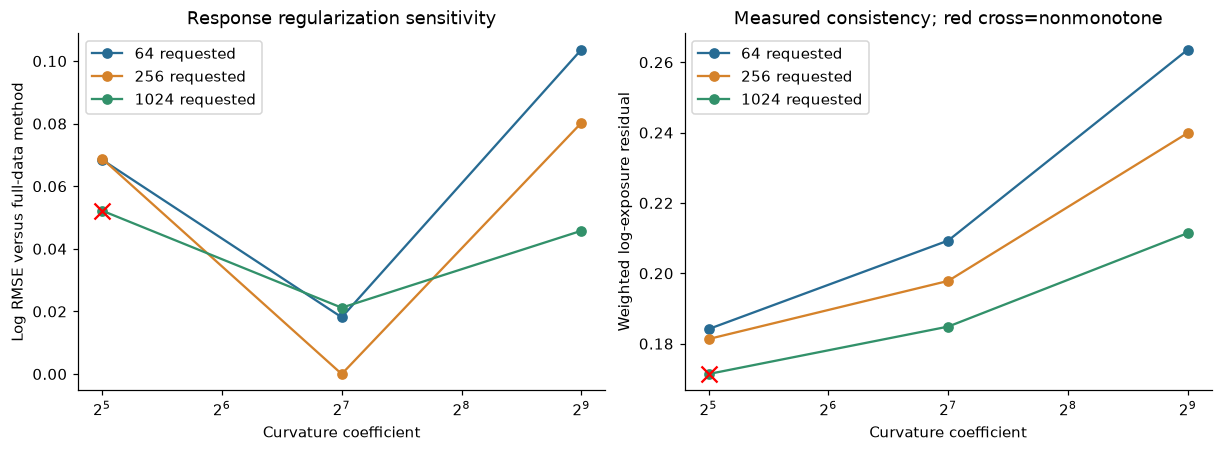

All response trials, including physical failures: [
  {
    "samples": 64,
    "lambda": 32.0,
    "kept": 25,
    "log_rmse": 0.06848165430879855,
    "log_exposure_residual": 0.18414602286573273,
    "monotone": true,
    "runtime_s": 0.6522118999855593
  },
  {
    "samples": 64,
    "lambda": 128.0,
    "kept": 25,
    "log_rmse": 0.018128947777195568,
    "log_exposure_residual": 0.20931267802375408,
    "monotone": true,
    "runtime_s": 0.7414462000015192
  },
  {
    "samples": 64,
    "lambda": 512.0,
    "kept": 25,
    "log_rmse": 0.10367534639172167,
    "log_exposure_residual": 0.2636009536332748,
    "monotone": true,
    "runtime_s": 0.6170576000004075
  },
  {
    "samples": 256,
    "lambda": 32.0,
    "kept": 65,
    "log_rmse": 0.06882719207042033,
    "log_exposure_residual": 0.18131602397220764,
    "monotone": true,
    "runtime_s": 0.809991899994202
  },
  {
    "samples": 256,
    "lambda": 128.0,
    "kept": 65,
    "log_rmse": 0.0,
    "log_exposure_residual":

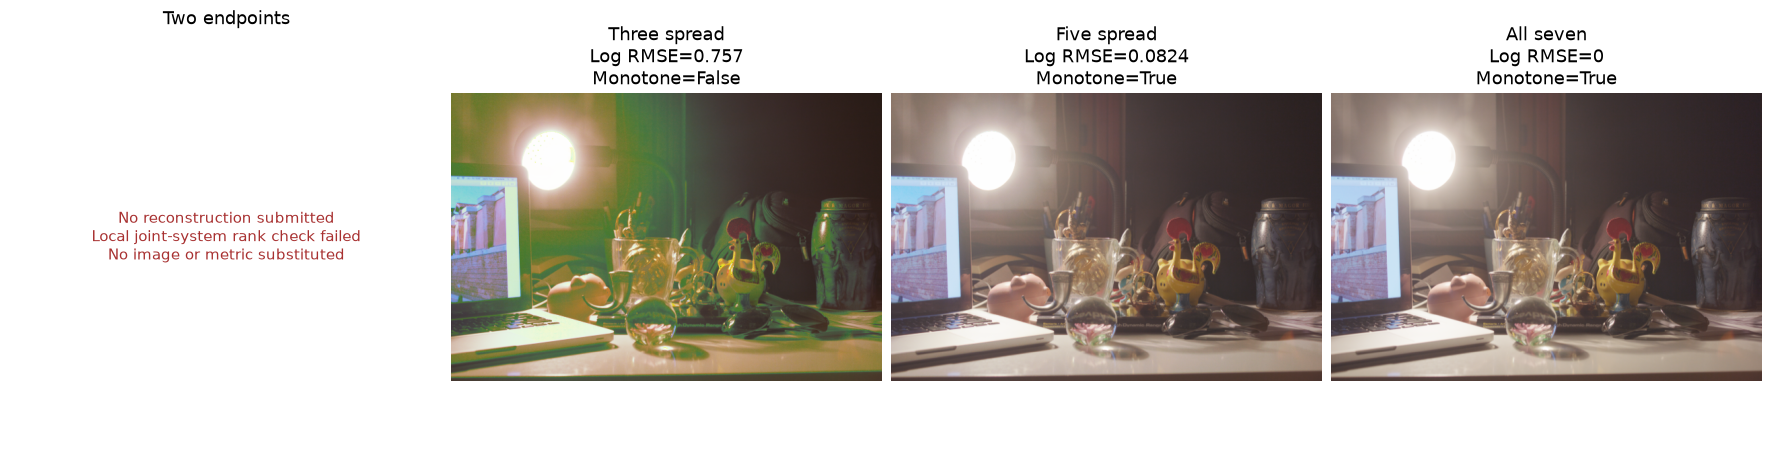

{
  "Two endpoints": {
    "status": "rejected_by_local_rank_check",
    "error": "Response system is rank deficient"
  },
  "Three spread": {
    "ncc": 0.8895558522924395,
    "log_rmse": 0.7573068099284487,
    "status": "computed",
    "monotone": false
  },
  "Five spread": {
    "ncc": 0.9995119594393576,
    "log_rmse": 0.08235792701816105,
    "status": "computed",
    "monotone": true
  },
  "All seven": {
    "ncc": 0.9999999999999998,
    "log_rmse": 0.0,
    "status": "computed",
    "monotone": true
  }
}


In [6]:
sensitivity=[]
for count in [64,256,1024]:
    for smooth in [32.,128.,512.]:
        t0=time.perf_counter();r=reconstruct(frames,times,count,smooth)
        sensitivity.append({'samples':count,'lambda':smooth,'kept':len(sample_stack(frames,times,count)),
            'log_rmse':agreement(r['reconstruction'],fresh['reconstruction'])['log_rmse'],
            'log_exposure_residual':log_exposure_residual(frames,times,r['reconstruction'][0],r['response'][0]),'monotone':bool(np.all(np.diff(r['response'][0],axis=0)>0)),'runtime_s':time.perf_counter()-t0})
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for count,color in zip([64,256,1024],['#276b93','#d5822a','#32916a']):
    rows=[r for r in sensitivity if r['samples']==count]
    axs[0].plot([r['lambda'] for r in rows],[r['log_rmse'] for r in rows],'o-',label=f'{count} requested',color=color)
    axs[1].plot([r['lambda'] for r in rows],[r['log_exposure_residual'] for r in rows],'o-',label=f'{count} requested',color=color)
    bad=[r for r in rows if not r['monotone']]
    for ax,key in zip(axs,['log_rmse','log_exposure_residual']):ax.scatter([r['lambda'] for r in bad],[r[key] for r in bad],marker='x',s=110,color='red',zorder=5)
axs[0].set(ylabel='Log RMSE versus full-data method',title='Response regularization sensitivity')
axs[1].set(ylabel='Weighted log-exposure residual',title='Measured consistency; red cross=nonmonotone')
for ax in axs:ax.set_xscale('log',base=2);ax.set_xlabel('Curvature coefficient');ax.legend()
plt.show()
print('All response trials, including physical failures:',json.dumps(sensitivity,indent=2))
subsets={'Two endpoints':[0,6],'Three spread':[0,3,6],'Five spread':[0,1,3,5,6],'All seven':list(range(7))}
subset_results={};subset_metrics={}
for label,indices in subsets.items():
    try:
        r=reconstruct(frames[indices],times[indices]);subset_results[label]=r
        subset_metrics[label]=dict(agreement(r['reconstruction'],fresh['reconstruction']),status='computed',monotone=bool(np.all(np.diff(r['response'][0],axis=0)>0)))
    except ValueError as exc:
        subset_results[label]=None;subset_metrics[label]={'status':'rejected_by_local_rank_check','error':str(exc)}
fig,axs=plt.subplots(1,4,figsize=(16,4),layout='constrained')
for ax,(label,r) in zip(axs,subset_results.items()):
    if r is None:
        ax.text(.5,.5,'No reconstruction submitted\nLocal joint-system rank check failed\nNo image or metric substituted',ha='center',va='center',wrap=True,color='#a83131');ax.set_title(label)
    else:
        ax.imshow(display_rgb(r['reconstruction'][0]));ax.set_title(f'{label}\nLog RMSE={subset_metrics[label]["log_rmse"]:.3g}\nMonotone={subset_metrics[label]["monotone"]}')
    ax.axis('off')
plt.show()
print(json.dumps(subset_metrics,indent=2))


### Supplementary perturbations and spatial detail
The next experiment deliberately adds synthetic digital noise to the measured photographs. It tests sensitivity to additional corruption;the deposited benchmark remains unchanged. Four independent perturbations at each noise level are all reported. Bright-window and interior profiles are drawn from the same fresh full-image reconstruction,without a quantitative evaluation crop.

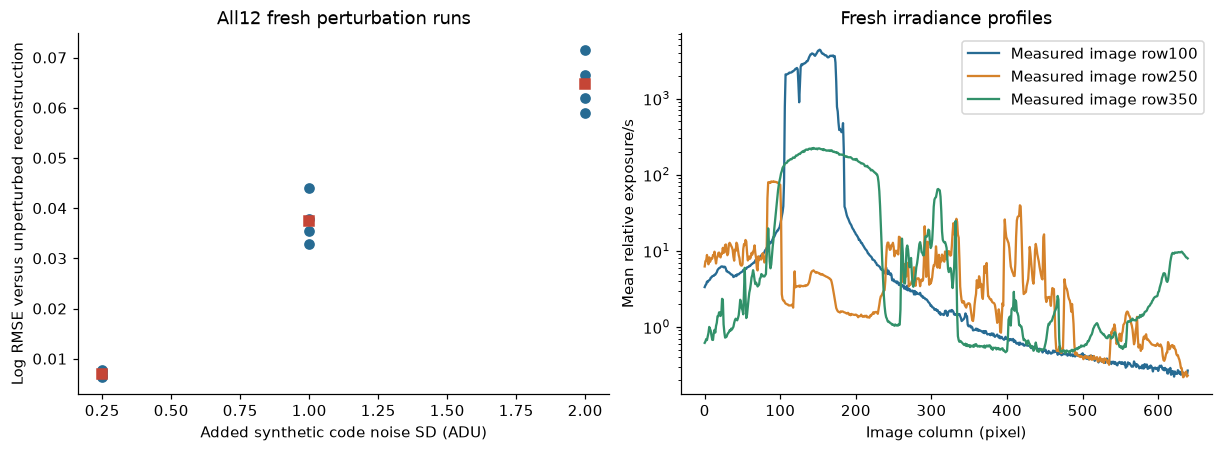

5179

In [7]:
noise_results=[];rng=np.random.default_rng(20261027)
for sigma in [.25,1.,2.]:
    for repeat in range(4):
        noisy=np.clip(np.rint(frames.astype(float)+rng.normal(0,sigma,frames.shape)),0,255).astype(np.uint8)
        r=reconstruct(noisy,times)
        noise_results.append({'added_sigma_adu':sigma,'repeat':repeat,'log_rmse':agreement(r['reconstruction'],fresh['reconstruction'])['log_rmse']})
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for sigma in [.25,1.,2.]:
    vals=[r['log_rmse'] for r in noise_results if r['added_sigma_adu']==sigma]
    axs[0].scatter([sigma]*len(vals),vals,color='#276b93');axs[0].plot(sigma,np.mean(vals),'s',color='#c54536')
axs[0].set(xlabel='Added synthetic code noise SD (ADU)',ylabel='Log RMSE versus unperturbed reconstruction',title='All12 fresh perturbation runs')
for row,color in [(100,'#276b93'),(250,'#d5822a'),(350,'#32916a')]:axs[1].semilogy(lum[row],label=f'Measured image row{row}',color=color)
axs[1].set(xlabel='Image column (pixel)',ylabel='Mean relative exposure/s',title='Fresh irradiance profiles');axs[1].legend();plt.show()
measurements={'runtime_s':runtime,'judge':report,'baseline_parity':baseline_parity,'per_exposure_forward_adu':per_exposure,'sensitivity':sensitivity,'exposure_subsets':subset_metrics,'synthetic_noise':noise_results}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding='utf8')


## Conclusion
The active full-data path recovers a relative irradiance field and camera response that reproduce the original numerical implementation. The measured forward residual remains several ADU;the physical camera/JPEG model is approximate and no independent GT is available. Response assumptions,regularization,sample selection and shutter coverage all affect the inferred photometry,as the fresh comparisons show. Saturation limits,possible scene changes and absent RAW/noise calibration remain scientific limitations. Display tone maps illustrate recovered detail but are not the benchmark targets.

Sources: Debevec and Malik,SIGGRAPH1997;Banterle etal.,Advanced High Dynamic Range Imaging,2ndedition2017. Exact code revision,data hashes,original-run records and implementation conventions are documented in the private validation evidence.